In [1]:
from __future__ import annotations

import sys
from pathlib import Path
from tqdm import trange
import numpy as np
ROOT = Path.cwd().resolve()
while ROOT.name and not (ROOT / 'hidden_sector_DM').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from hidden_sector_DM.HiddenSectorDM import VectorPortal, BaryonPortal, HiggsPortal 

from GCE.likelihood import cascade_template, gls_fit, measurement   # noqa: E402
from GCE.pythia_runner import DEFAULT_SEED                     # noqa: E402
from scipy.ndimage import shift as ndimage_shift
from GCE.halo import HALO_2112, RHO_LOCAL_PRIOR
import numpy as np
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.path import Path as MplPath
from matplotlib.tri import Triangulation, LinearTriInterpolator
from scipy.ndimage import gaussian_filter, gaussian_filter1d
import time
from hidden_sector_DM.HiddenSectorDM import Cosmology, BoltzmannSolver, s0_cosmo, rhoc
from GCE.spectrum import GEVM2_TO_CM3S
from scipy.optimize import brentq
from scipy.interpolate import griddata
plt.style.use(ROOT / 'notebooks' / 'mine.mplstyle')
plt.rcParams['axes.axisbelow'] = False

In [2]:
# ---- configuration -------------------------------------------------------
MX_LIM = (15.0, 100.0)   # GeV
MY_LIM = (5.0, 100.0)    # GeV, capped from above by mX
N_POINTS = 16384
N_COLS = 124
DECIMALS = 2

def triangle_grid(n_points: int = N_POINTS, n_cols: int = N_COLS,
                  mx_lim=MX_LIM, my_lim=MY_LIM, decimals: int = DECIMALS):
    """The grid as a (2, `n_points`) array of (mX, mY) in GeV."""
    u = np.linspace(*np.log10(mx_lim), n_cols)          # log10 mX per column
    v_lo = np.log10(my_lim[0])
    v_hi = np.minimum(u, np.log10(my_lim[1]))           # the mY <= mX edge
    height = v_hi - v_lo
    if not (height > 0).all():
        raise ValueError("some column has no room in mY; check the limits")

    # Points per column, proportional to column height.  Largest-remainder
    # apportionment, so the total is exactly `n_points`.
    raw = height / height.sum() * n_points
    n = np.floor(raw).astype(int)
    short = n_points - n.sum()
    if short:
        n[np.argsort(n - raw)[:short]] += 1
    if n.min() < 2:
        raise ValueError(f"column of {n.min()} point(s): lower N_COLS")

    mX = np.repeat(10.0 ** u, n)
    mY = np.concatenate([10.0 ** np.linspace(v_lo, hi, k)
                         for hi, k in zip(v_hi, n)])
    return np.round(np.vstack([mX, mY]), decimals)

STRIDE = 1

def thin(grid, stride: int):
    """Every `stride`-th point in both directions, trapezoid edges kept."""
    if stride == 1:
        return grid
    mX = grid[0]
    starts = np.flatnonzero(np.r_[True, np.diff(mX) != 0.0])   # column starts
    ends = np.r_[starts[1:], mX.size]
    cols = np.unique(np.r_[np.arange(0, starts.size, stride), starts.size - 1])
    keep = np.concatenate([
        np.unique(np.r_[np.arange(starts[c], ends[c], stride), ends[c] - 1])
        for c in cols])
    return grid[:, keep]


GRID = thin(triangle_grid(), STRIDE)    # (2, n) masses in GeV
MX_GRID, MY_GRID = GRID         # flat, one entry per point -- not two axes
print(f"{GRID.shape[1]} of {N_POINTS} points, "
      f"{np.unique(MX_GRID).size} of {N_COLS} mX columns  (STRIDE={STRIDE})")

REGION = "south"        # 'both' (40x40), 'south' or 'north'
N_EVENTS = 400_000      # what the channel_spectra cache holds
SEED = DEFAULT_SEED
ALPHAX = 1e-2           # the dataclass wants a value; it cannot reach the fit

# ---- the fit -------------------------------------------------------------

phi, Cinv = measurement(region=REGION)      # once; independent of the model

n_pts = GRID.shape[1]
chi2 = np.full(n_pts, np.nan)
ts = np.full((n_pts, 14), np.nan)
sigmav = np.full(n_pts, np.nan)
sigmav_err = np.full(n_pts, np.nan)

for k in trange(n_pts):
    mX, mY = (float(v) for v in GRID[:, k])
    model = VectorPortal(mX=mX, mY=mY, gX=2, gY=3, alphaX=ALPHAX)
    t = cascade_template(model, n_events=N_EVENTS, seed=SEED)
    ts[k] = t
    sigmav[k], sigmav_err[k], chi2[k] = gls_fit(t, phi, Cinv)

k_best = int(np.nanargmin(chi2))
print(f"\nbest fit: mX={MX_GRID[k_best]:g}, mY={MY_GRID[k_best]:g}, "
      f"chi2={chi2[k_best]:.2f} / {14 - 3} dof")

16384 of 16384 points, 124 of 124 mX columns  (STRIDE=1)


 ... (more hidden) ...


best fit: mX=32.94, mY=20.01, chi2=18.05 / 11 dof


In [5]:
# ============================================================================
# (mX, <sigma v>) region with the local DM density uncertainty folded into the
# chi2, so the contour inflates smoothly instead of being widened by hand into a
# flat-topped band.  Self-contained: rebuilds the fixed-halo surface on its own
# (wide) <sigma v> axis, then profiles rho_local out of it.
# ============================================================================
sigmav_axis = np.logspace(-27, -24, 700)
sigmav_log_step = np.diff(np.log(sigmav_axis))[0]
mx_columns = np.unique(MX_GRID)
chi2_fixed_halo = np.full((sigmav_axis.size, mx_columns.size), np.nan)
for j in trange(len(mx_columns)):
    mx=mx_columns[j]
    in_column = ((MX_GRID == mx) & np.isfinite(chi2)
                 & np.isfinite(sigmav) & np.isfinite(sigmav_err))
    if not in_column.any():
        continue
    sv_hat, sv_err, chi2_min = (sigmav[in_column], sigmav_err[in_column],
                                chi2[in_column])
    parabola = chi2_min + ((sigmav_axis[:, None] - sv_hat) / sv_err) ** 2
    chi2_fixed_halo[:, j] = parabola.min(axis=1)

# rho_local prior -> chi2 penalty on the log Jbar rescaling.
rho_mean, rho_sigma = RHO_LOCAL_PRIOR # (0.44, 0.13) GeV/cm^3
rho_lognormal_width = rho_sigma / rho_mean
rho_samples = rho_mean * np.exp(np.linspace(-4, 4, 201) * rho_lognormal_width)
ln_jbar_offset = 2.0 * np.log(rho_samples / HALO_2112["rho_local"])          # u
halo_penalty = (np.log(rho_samples / rho_mean) / rho_lognormal_width) ** 2   # P(u)
chi2_marginalised = np.full_like(chi2_fixed_halo, np.inf)
for u, penalty in zip(ln_jbar_offset, halo_penalty):
    shifted = ndimage_shift(chi2_fixed_halo, (-u / sigmav_log_step, 0),
                            order=1, cval=np.inf, mode="constant")
    np.minimum(chi2_marginalised, shifted + penalty, out=chi2_marginalised)

dchi2_fixed_halo = chi2_fixed_halo - np.nanmin(chi2_fixed_halo)
dchi2_marginalised = chi2_marginalised - np.nanmin(chi2_marginalised)

 ... (more hidden) ...


In [6]:
def smoothed_field(mX, mY, dchi2, n_interp=400, sigma=0.5, rezero=True):
    """Delta-chi2 on a regular log grid, lightly smoothed.

    Triangulates in log10 space, interpolates, then smooths with a normalized
    convolution so the domain edge doesn't bleed inward.  Returns (xi, yi, zs)
    with xi, yi in linear GeV; outside the hull is NaN.

    `rezero` subtracts the field's own post-smoothing minimum.  That is only
    correct for a field whose true (pre-smoothing) floor is exactly 0, i.e. a
    profiled chi2 - chi2_best field such as `zs` -- there the subtraction just
    undoes the tiny numerical lift smoothing introduces.  A "+relic" subset
    field (fixed sigma v rather than profiled) generally has a real, physical
    floor above 0 (forcing sigma v to one value costs real chi2 even at its
    best mass point); self-re-zeroing such a field would silently strip that
    cost out and shift the whole field down, inflating the region it plots
    as "allowed" -- pass `rezero=False` for those.
    """
    xl, yl = np.log10(mX), np.log10(mY)
    xi, yi = np.meshgrid(np.linspace(xl.min(), xl.max(), n_interp),
                         np.linspace(yl.min(), yl.max(), n_interp))
    zi = LinearTriInterpolator(Triangulation(xl, yl), dchi2)(xi, yi)
    if sigma > 0:
        m = (~np.ma.getmaskarray(zi)).astype(float)      # 1 inside, 0 outside
        z = np.ma.filled(zi, 0.0) * m
        num, den = (gaussian_filter(a, sigma, mode="nearest") for a in (z, m))
        zs = np.where(den > 1e-3, num / np.maximum(den, 1e-12), np.nan)
    else:
        zs = np.ma.filled(zi.astype(float), np.nan)
    if rezero:
        zs = zs - np.nanmin(zs)   # only valid when the true floor is 0
    return 10.0**xi, 10.0**yi, zs
    
def color_shades(color, n, lightest_alpha=0.25):
    """Generate n shades from `color` to lighter, blended toward white.

    Parameters
    ----------
    color : str or RGB tuple
        Base color (e.g. "tab:blue").
    n : int
        Number of shades.
    lightest_alpha : float
        Fraction of base color in the lightest shade (0=white, 1=original).

    Returns
    -------
    list of hex color strings, from darkest to lightest.
    """
    rgb = np.array(mcolors.to_rgb(color))
    white = np.array([1.0, 1.0, 1.0])
    fracs = np.linspace(1.0, lightest_alpha, n)
    return [mcolors.to_hex(rgb * f + white * (1 - f)) for f in fracs]

In [7]:
xi, yi, zs = smoothed_field(MX_GRID, MY_GRID, chi2 - chi2[k_best],sigma=2)
dchi2_fixed_halo_smooth   = gaussian_filter1d(dchi2_fixed_halo,   1, axis=1, mode="nearest")
dchi2_marginalised_smooth = gaussian_filter1d(dchi2_marginalised, 1, axis=1, mode="nearest")

In [8]:
OCH2_TARGET  = 0.12
N_MX_COARSE  = 46            # coarse (log10 mX, log10 mY/mX) grid, interpolated onto GRID
N_RV_COARSE  = 34
RV_MAX       = 0.98          # XX -> YY shuts off at mY = mX
ALPHAX_RANGE = (1e-5, 1.0)   # perturbative ceiling alpha_X = gX^2 / 4pi < 1
RELIC_RTOL   = 3e-3

cosmo = Cosmology()

EPS_JOINT    = (1e-9, 1e-10)
EPS_SECLUDED = (1e-11, 5e-12, 1e-12)

ALPHAX_PERT_MAX = 0.1    # alpha_X above this is non-perturbative -- model.py's
                         # tree-level rates do not apply there, and it is where the
                         # folded-Omega(alpha_X) values live (anchor check: 0/3 at
                         # xi=2.5, eps=1e-11, rv=0.95).  The bare axis test is NOT
                         # enough: the secluded and eps=1e-10 outputs carry an
                         # alpha_X axis topping out at 1.0, so it passes alpha ~ 1.
RV_CEILING = {
    1e-9:  {"": 0.96, "xi_ini_0.5_": 0.96, "xi_ini_2.5_": 0.61},
    1e-10: 0.9,
    1e-11: 0.90, 5e-12: 0.90, 1e-12: 0.90,
}

def _rv_ceiling(EPS_DISPLAY, xi_string):
    c = RV_CEILING[EPS_DISPLAY]
    return c[xi_string] if isinstance(c, dict) else c

_COMMON_RV_CACHE = {}

def _common_rv(EPS_DISPLAY, xi_strings=("", "xi_ini_0.5_", "xi_ini_2.5_")):
    """rv values carrying data in EVERY xi grid at this eps.

    The xi=1 baseline is 34 rv columns deep (eps=1e-10, secluded) or 35 of 67
    filled (eps=1e-9); both variants are 67/67.  Letting griddata build the
    baseline contour from a mesh half as dense as the ones it is plotted against
    injects the rv-interpolation bias the rv=0.9085 campaign measured at 7.7%
    straight into the xi comparison.  34 embeds exactly in 67 (old j -> new 2j,
    verified to 0.0), so the shared columns are well defined.
    """
    if EPS_DISPLAY in _COMMON_RV_CACHE:
        return _COMMON_RV_CACHE[EPS_DISPLAY]
    sets = []
    for xs in xi_strings:
        if EPS_DISPLAY in EPS_SECLUDED:
            d = np.load(f"../output/relic/relic_grid_vP_{xs}eps_secluded.npz")
            a = d["coupling_relic"][int(np.flatnonzero(d["eps"] == EPS_DISPLAY)[0])]
        else:
            d = np.load(f"../output/relic/relic_grid_vP_{xs}eps{EPS_DISPLAY:.0e}.npz")
            a = d["coupling_relic"]
        sets.append({round(v, 6)
                     for v in (10.0 ** d["log_rv"])[np.isfinite(a).any(axis=0)]})
    out = np.array(sorted(set.intersection(*sets)))
    _COMMON_RV_CACHE[EPS_DISPLAY] = out
    return out


def get_sv_relic_at_eps(EPS_DISPLAY,xi_string):
    if EPS_DISPLAY in EPS_SECLUDED:
        relic = np.load("../output/relic/relic_grid_vP_"+xi_string+"eps_secluded.npz")
        e_idx = int(np.flatnonzero(relic["eps"] == EPS_DISPLAY)[0])
        alphaX_c_eps = relic["coupling_relic"][e_idx]
    else:
        relic = np.load("../output/relic/relic_grid_vP_"+xi_string+f"eps{EPS_DISPLAY:.0e}.npz")
        alphaX_c_eps = relic["coupling_relic"]
    LMX_C_eps, LRV_C_eps = np.meshgrid(relic["log_mX"], relic["log_rv"], indexing="ij")

    # keep only coarse nodes that are (a) an interpolated -- not extrapolated --
    # read of the sampled Omega h^2(alpha_X) curve, (b) perturbative, (c) inside
    # the anchor-validated rv band, and (d) on an rv column the xi=1 baseline
    # also carries, so all three xi are interpolated off the same mesh.
    axis = relic["coupling_axis"]
    rv_c = np.round(10.0 ** LRV_C_eps, 6)
    rv_cap = _rv_ceiling(EPS_DISPLAY, xi_string)
    ok_c_eps = (np.isfinite(alphaX_c_eps)
                & (alphaX_c_eps >= axis.min())
                & (alphaX_c_eps <= min(axis.max(), ALPHAX_PERT_MAX))
                & (rv_c <= rv_cap)
                & np.isin(rv_c, _common_rv(EPS_DISPLAY)))
    alphaX_relic_eps = 10.0 ** griddata(
        np.column_stack([LMX_C_eps[ok_c_eps], LRV_C_eps[ok_c_eps]]),
        np.log10(alphaX_c_eps[ok_c_eps]),
        np.column_stack([np.log10(MX_GRID), np.log10(MY_GRID / MX_GRID)]), method="linear")
    sv_relic_eps = np.full(n_pts, np.nan)
    for k in np.flatnonzero(np.isfinite(alphaX_relic_eps)):
        m = VectorPortal(mX=float(MX_GRID[k]), mY=float(MY_GRID[k]), gX=2, gY=3,
                     alphaX=float(alphaX_relic_eps[k]), include_antiparticlesX=True)
        sv_relic_eps[k] = m.sigmav_XX_to_YY_swave() * GEVM2_TO_CM3S
    fin_eps = np.isfinite(sv_relic_eps)
    """
    if EPS_DISPLAY<=1e-9:
        plt.tricontourf(MX_GRID[fin_eps], MY_GRID[fin_eps],np.log10(sv_relic_eps[fin_eps]) , levels=20, cmap='viridis')
        #plt.tricontourf(MX_GRID[fin_eps], MY_GRID[fin_eps],sv_relic_eps[fin_eps] , levels=20, cmap='viridis')
        plt.colorbar(label=r'$\langle \sigma v \rangle$')
        plt.show()
        plt.close()
    """
    R_eps = phi - sv_relic_eps[fin_eps, None] * ts[fin_eps]
    dchi2_relic_eps = np.full(n_pts, np.nan)
    dchi2_relic_eps[fin_eps] = np.einsum('ij,jk,ik->i', R_eps, Cinv, R_eps) - chi2[k_best]
    xe, ye, ze = smoothed_field(MX_GRID[fin_eps], MY_GRID[fin_eps], dchi2_relic_eps[fin_eps], sigma=2, rezero=False)
    # ---- same, with the local DM density marginalised (prior RHO_LOCAL_PRIOR) ----
    # as cells 7/8: sv_eff = sv_relic_eps * (rho_sun / 0.4)^2, rho_sun profiled out.
    rho_mean, rho_sigma = RHO_LOCAL_PRIOR
    rho_w = rho_sigma / rho_mean
    rho_samples = rho_mean * np.exp(np.linspace(-4, 4, 201) * rho_w)
    fac = (rho_samples / HALO_2112["rho_local"]) ** 2
    pen = (np.log(rho_samples / rho_mean) / rho_w) ** 2
    rise_eps = ((sv_relic_eps[fin_eps, None] * fac - sigmav[fin_eps, None]) / sigmav_err[fin_eps, None]) ** 2 + pen
    dchi2_relic_eps_marg = np.full(n_pts, np.nan)
    dchi2_relic_eps_marg[fin_eps] = (chi2[fin_eps] - chi2[k_best]) + rise_eps.min(axis=1)
    xe_marg, ye_marg, ze_marg = smoothed_field(MX_GRID[fin_eps], MY_GRID[fin_eps],
                                          dchi2_relic_eps_marg[fin_eps], sigma=2, rezero=False)
    return {'xe':xe,'ye':ye,'ze':ze,
            'xe_marg':xe_marg,'ye_marg':ye_marg,'ze_marg':ze_marg,
            'sv_relic_eps':sv_relic_eps}

In [9]:
xis_str=["","xi_ini_0.5_","xi_ini_2.5_"]
epss_info=[]
for i in trange(len(xis_str)):
    eps1_info=get_sv_relic_at_eps(1e-9, xis_str[i])
    eps2_info=get_sv_relic_at_eps(1e-10, xis_str[i])
    eps3_info=get_sv_relic_at_eps(1e-11, xis_str[i])
    eps4_info=get_sv_relic_at_eps(5e-12, xis_str[i])
    epss_info.append([eps1_info,eps2_info,eps3_info])
#eps5_info=get_sv_relic_at_eps(1e-12)

 ... (more hidden) ...


No handles with labels found to put in legend.
 ... (more hidden) .../tmp/ipykernel_3429775/609783985.py:32: UserWarning: No contour levels were found within the data range.
  axs[i].contour(epss_info[2][i]['xe_marg'], epss_info[2][i]['ye_marg'], epss_info[2][i]['ze_marg'], levels=[9.2], colors=css[2][0], zorder=3.1, lw=1)
/tmp/ipykernel_3429775/609783985.py:32: UserWarning: The following kwargs were not used by contour: 'lw'
  axs[i].contour(epss_info[2][i]['xe_marg'], epss_info[2][i]['ye_marg'], epss_info[2][i]['ze_marg'], levels=[9.2], colors=css[2][0], zorder=3.1, lw=1)
/tmp/ipykernel_3429775/609783985.py:33: UserWarning: The following kwargs were not used by contour: 'lw'
  axs[i].contour(epss_info[1][i]['xe_marg'], epss_info[1][i]['ye_marg'], epss_info[1][i]['ze_marg'], levels=[9.2], colors=css[1][0], zorder=3.2, lw=1)
/tmp/ipykernel_3429775/609783985.py:34: UserWarning: The following kwargs were not used by contour: 'lw'
  axs[i].contour(epss_info[0][i]['xe_marg'], epss_info[0][

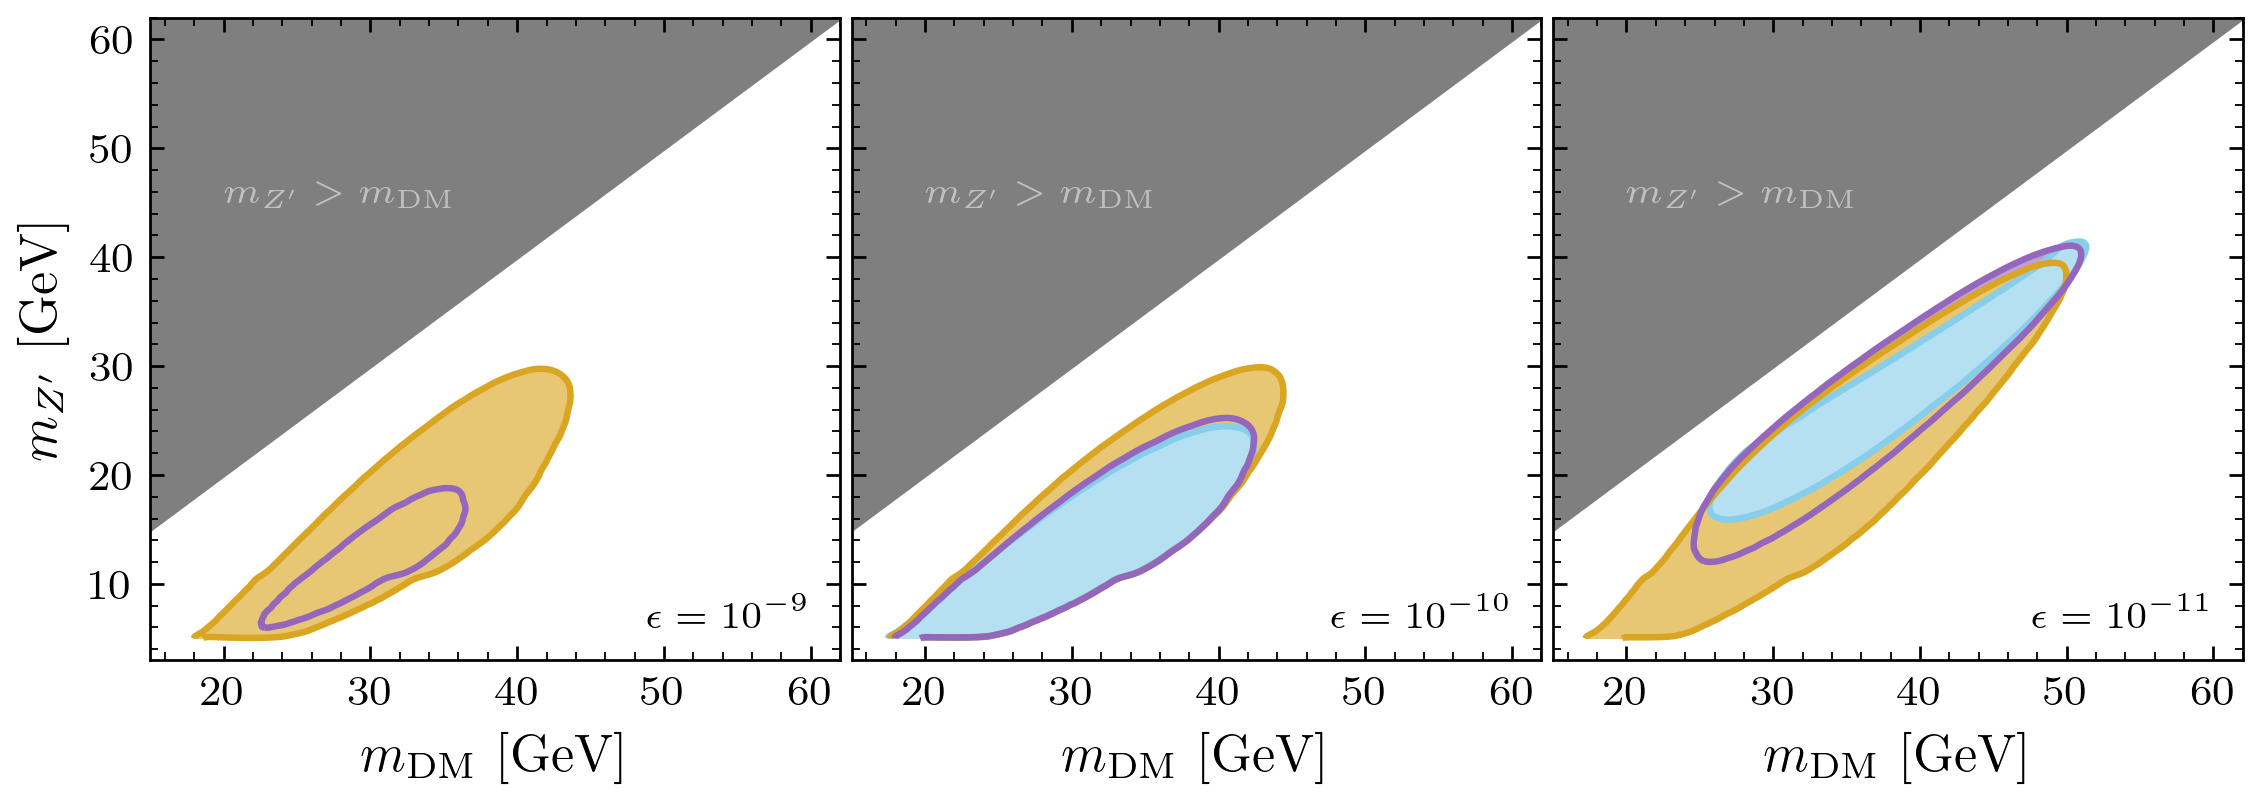

In [10]:
# ---- GCE region, thermalised relic subset, and the eps=EPS_DISPLAY (diluted)
# relic subset, fixed rho_odot and marginalised over RHO_LOCAL_PRIOR --
# starting benchmark, edit freely ----
_golden_ratio_=1.61803398875

css=[ color_shades('tab:purple', 3), color_shades('goldenrod', 3),color_shades('skyblue', 3)]
eps_list = (1e-9, 1e-10, 1e-11)   # panel order, matching how cell 7 fills epss_info
eps_tex= [r'$\epsilon=10^{-9}$',
          r'$\epsilon=10^{-10}$',
          r'$\epsilon=10^{-11}$'
         ]
fig= plt.figure(figsize=(7.5, 7.5/_golden_ratio_*0.5))
mDMs = np.linspace(10, 70, 50)
gs = GridSpec(40, 30, figure=fig)  # 7 rows and 7 columns for the triangle plot

ax1= fig.add_subplot(gs[:, :10])
ax2= fig.add_subplot(gs[:,10:20])
ax3= fig.add_subplot(gs[:,20:30])
axs=[ax1,ax2,ax3]
#ax2.scatter(np.NaN, np.NaN, marker='s',s=10,color=css[2][1], ecolor=css[2][0],zorder=3.1, lw=1,label=r'$\xi_{0}=0.5$')
ax2.legend()
for i in trange(len(axs)):
    axs[i].set_xlim(15,62)
    axs[i].set_xticks([20,30,40,50,60])
    axs[i].set_ylim(3, 62)
    axs[i].set_yticks([10,20,30,40,50,60])
    if i!=0:
        axs[i].set_yticklabels([])
    axs[i].contourf(epss_info[0][i]['xe_marg'], epss_info[0][i]['ye_marg'], epss_info[0][i]['ze_marg'], levels=[0,9.2], colors=[css[0][1]], zorder=3)
    axs[i].contourf(epss_info[1][i]['xe_marg'], epss_info[1][i]['ye_marg'], epss_info[1][i]['ze_marg'], levels=[0, 9.2], colors=[css[1][1]], zorder=3)
    axs[i].contourf(epss_info[2][i]['xe_marg'], epss_info[2][i]['ye_marg'], epss_info[2][i]['ze_marg'], levels=[0, 9.2], colors=[css[2][1]], zorder=3)
    axs[i].contour(epss_info[2][i]['xe_marg'], epss_info[2][i]['ye_marg'], epss_info[2][i]['ze_marg'], levels=[9.2], colors=css[2][0], zorder=3.1, lw=1)
    axs[i].contour(epss_info[1][i]['xe_marg'], epss_info[1][i]['ye_marg'], epss_info[1][i]['ze_marg'], levels=[9.2], colors=css[1][0], zorder=3.2, lw=1)
    axs[i].contour(epss_info[0][i]['xe_marg'], epss_info[0][i]['ye_marg'], epss_info[0][i]['ze_marg'], levels=[9.2], colors=css[0][0], zorder=3.3, lw=1)
    axs[i].fill_between(mDMs,mDMs,np.ones(len(mDMs))*1e4,zorder=2, color='tab:grey')
    # Hatch above the last common rv column the LOOSEST curve in this panel
    # reaches (see RV_CEILING).  Where one xi is cut tighter than the others --
    # eps=1e-9, xi=2.5 -- that contour simply ends earlier, inside the
    # un-hatched area.
    _rv_cols = _common_rv(eps_list[i])
    _cap = max(_rv_ceiling(eps_list[i], xs) for xs in xis_str)
    rv_edge = _rv_cols[_rv_cols <= _cap].max()
    #axs[i].fill_between(mDMs, rv_edge*mDMs, mDMs, facecolor='none',
    #                    hatch='///', edgecolor='silver', linewidth=0.0, zorder=2.4)
    axs[i].text(20, 45, r"$m_{Z^\prime}>m_{\rm DM}$", color="silver",
        fontsize=mpl.rcParams['legend.fontsize'], ha='left',zorder=10)
    axs[i].text(60,6,eps_tex[i], fontsize=mpl.rcParams['legend.fontsize'], ha='right')
    axs[i].set_xlabel(r"$m_{\rm DM}\,\,[{\rm GeV}]$")
ax1.set_ylabel(r"$m_{Z^\prime}\,\,[{\rm GeV}]$")
#ax.contourf(eps1_info['xe_marg'], eps1_info['ye_marg'], eps1_info['ze_marg'], levels=[0, 2.30,9.12], colors=[cs1[0],cs1[1]], zorder=3)

plt.show()
plt.close()